# 22_SVM_Model_Tuning

# SVM Model Tuning and Optimization

## Learning Objectives

- Feature Scaling이 SVM Prediction에 어떤 영향을 주는지 이해한다.
- RBF Kernel의 `gamma`가 Decision Boundary를 어떻게 바꾸는지 확인한다.
- `C`와 `gamma`의 조합에 따라 Model 성능이 달라짐을 확인한다.
- Cross-Validation으로 Hyperparameter를 비교하고 `GridSearchCV`로 적절한 조합을 선택한다.
- 최종 Model은 별도로 보관한 Test Data에서 한 번 평가한다.

## Problem

21강에서 Linear SVM과 RBF SVM을 사용해 `twisted_data.csv`를 분류했다.

RBF SVM을 선택했다고 해서 하나의 Model이 정해지는 것은 아니다.

같은 Training Data에서도 Feature의 Scale, `C`, `gamma`에 따라 Decision Boundary가 달라진다.

이번 강의에서는 다음 순서로 Model을 개선한다.

`Data → Train/Test Split → Feature Scaling → Gamma Experiment → Cross-Validation → Grid Search → Final Test`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

drive.mount('/content/drive')
data_path = '/content/drive/My Drive/Colab Notebooks/0_ML/Input/'

Mounted at /content/drive


## Data — Twisted Classes

21강에서 사용한 두 Feature의 Binary Classification Data를 다시 사용한다.

- `x1`, `x2`: Input Features
- `y`: Class Label (0 또는 1)

이번에는 새로운 Classification 방법을 배우기보다, 같은 SVM의 Parameter가 결과를 어떻게 바꾸는지 분석한다.

Data Shape: (1000, 3)
Class Counts:
y
0    523
1    477
Name: count, dtype: int64


,x1,x2,y
0,-0.708553,-0.648847,0
1,0.326029,-0.551734,0
2,-3.105980,0.149616,0
3,-0.529565,-0.812004,0
4,2.837286,-0.176169,1


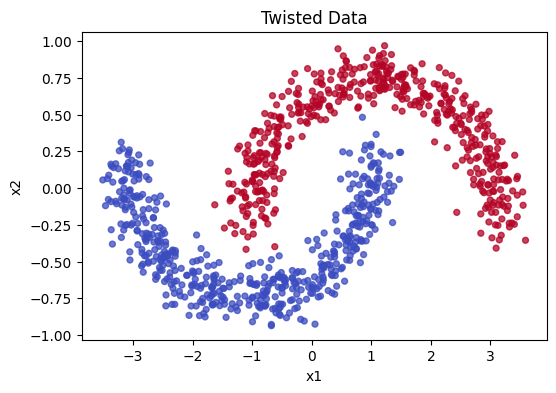

In [2]:
# 이전 강의에서 사용한 Data를 불러온다.
df = pd.read_csv(data_path + 'twisted_data.csv')
df = df[['x1', 'x2', 'y']]

print('Data Shape:', df.shape)
print('Class Counts:')
print(df['y'].value_counts().sort_index())
display(df.head())

X = df[['x1', 'x2']]
y = df['y']

plt.figure(figsize=(6, 4))
plt.scatter(X['x1'], X['x2'], c=y, cmap='coolwarm', s=18, alpha=0.75)
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Twisted Data')
plt.show()

## SVM and Feature Distance

RBF SVM은 두 Sample 사이의 Distance를 사용한다.

두 Sample이 $X=(x_1,x_2)$, $Z=(z_1,z_2)$라면 Euclidean Distance는

$$
d(X,Z)=\sqrt{(x_1-z_1)^2+(x_2-z_2)^2}.
$$

예를 들어 `x1` 차이가 1, `x2` 차이가 100이라면 `x2` 차이가 Distance를 거의 결정한다.

이는 반드시 `x2`가 더 중요한 Feature이기 때문은 아니다. 단지 측정 단위가 다를 수 있다.

실제로 어떤 차이가 생기는지 보기 위해 원래 Data의 `x2`에 100을 곱해 보자.

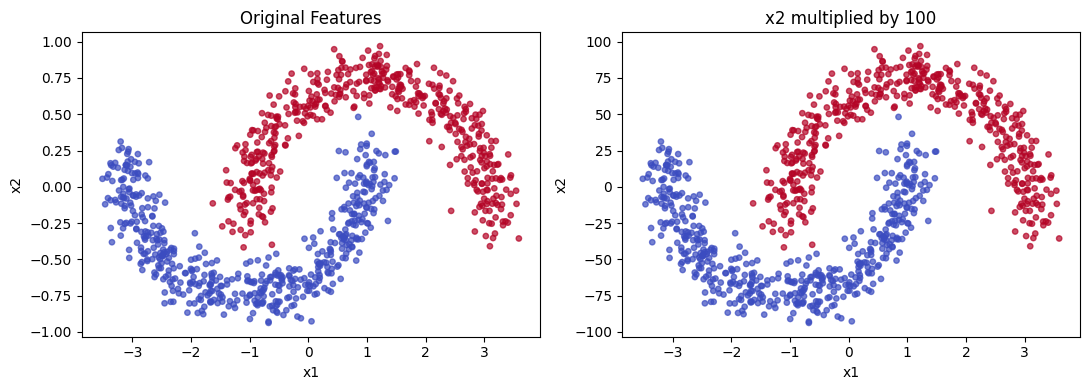

In [3]:
# Feature의 측정 단위만 인위적으로 변경한다.
X_distorted = X.copy()
X_distorted['x2'] = X_distorted['x2'] * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X['x1'], X['x2'], c=y, cmap='coolwarm', s=15, alpha=0.7)
axes[0].set_title('Original Features')
axes[1].scatter(X_distorted['x1'], X_distorted['x2'], c=y, cmap='coolwarm', s=15, alpha=0.7)
axes[1].set_title('x2 multiplied by 100')
for ax in axes:
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
plt.tight_layout()
plt.show()

## StandardScaler

`StandardScaler`는 Feature별로 Training Data의 Mean과 Standard Deviation을 사용해 값을 변환한다.

$$
z_j=\frac{x_j-\mu}{\sigma}
$$

- 변환 후 Training Data에서 각 Feature의 Mean은 약 0, Standard Deviation은 약 1이다.
- `StandardScaler`는 Class를 이용해 변환하지 않는다.
- 중요한 규칙: Test Data를 사용해 Mean과 Standard Deviation을 계산해서는 안 된다.

`Pipeline`으로 `StandardScaler`와 `SVC`를 연결하면 Scaling이 Training Data에서 학습되고, Test Data에도 같은 변환이 적용된다.

In [4]:
# 먼저 원래 Data를 Train/Test로 나눈다.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 동일한 Train/Test Sample에서 x2의 단위만 바꾼다.
X_train_distorted = X_train.copy()
X_test_distorted = X_test.copy()
X_train_distorted['x2'] *= 100
X_test_distorted['x2'] *= 100

# Scaling을 사용하지 않은 RBF SVM
model_without_scaling = SVC(kernel='rbf', C=1, gamma='scale')
model_without_scaling.fit(X_train_distorted, y_train)

# Training Data로 Scaling을 학습한 후 SVM에 전달한다.
model_with_scaling = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=1, gamma='scale')
)
model_with_scaling.fit(X_train_distorted, y_train)

print('Without Scaling:')
print('Train Accuracy:', round(model_without_scaling.score(X_train_distorted, y_train), 3))
print('Test Accuracy :', round(model_without_scaling.score(X_test_distorted, y_test), 3))
print()
print('With Scaling:')
print('Train Accuracy:', round(model_with_scaling.score(X_train_distorted, y_train), 3))
print('Test Accuracy :', round(model_with_scaling.score(X_test_distorted, y_test), 3))

Without Scaling:
Train Accuracy: 0.851
Test Accuracy : 0.895

With Scaling:
Train Accuracy: 0.996
Test Accuracy : 1.0


## Decision Boundary — With and Without Scaling

두 Model은 동일한 Training Samples를 사용했고, `x2`의 원래 정보도 같다.

차이는 Scaling 여부뿐이다.

Decision Boundary를 비교하여 Feature의 단위가 Prediction에 영향을 미치는지 확인한다.

`Pipeline`에 포함된 SVM의 Decision Boundary도 원래 좌표계에서 그릴 수 있다. Grid의 각 좌표를 `predict()`에 전달하면 `Pipeline`이 자동으로 Scaling을 처리하기 때문이다.

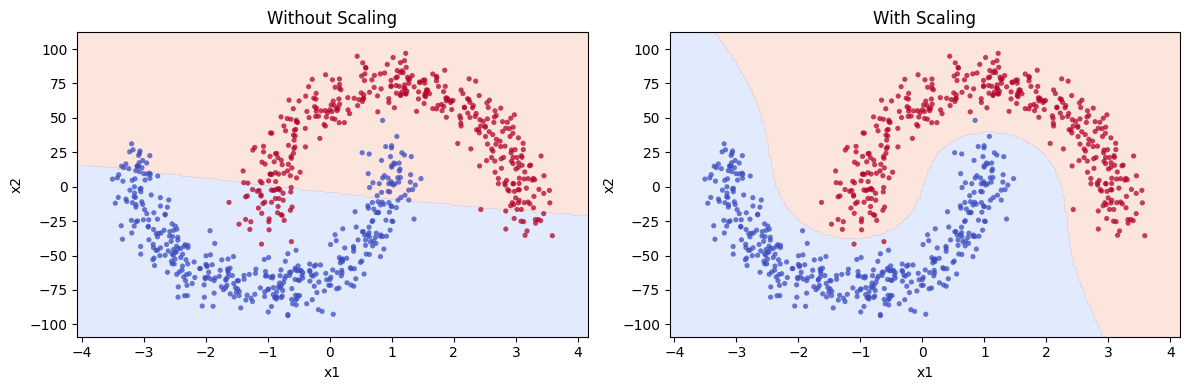

In [5]:
# 어떤 SVM이나 Pipeline에도 사용할 수 있는 Decision Boundary 함수
# X_plot의 Column 이름과 순서는 Training Data와 같아야 한다.
def plot_boundary(model, X_plot, y_plot, ax, title):
    x1_min, x1_max = X_plot['x1'].min(), X_plot['x1'].max()
    x2_min, x2_max = X_plot['x2'].min(), X_plot['x2'].max()
    pad1 = (x1_max - x1_min) * 0.08
    pad2 = (x2_max - x2_min) * 0.08

    xx1, xx2 = np.meshgrid(
        np.linspace(x1_min - pad1, x1_max + pad1, 220),
        np.linspace(x2_min - pad2, x2_max + pad2, 220)
    )
    grid = pd.DataFrame({'x1': xx1.ravel(), 'x2': xx2.ravel()})
    Z = model.predict(grid).reshape(xx1.shape)

    ax.contourf(xx1, xx2, Z, levels=[-0.5, 0.5, 1.5],
                cmap='coolwarm', alpha=0.25)
    ax.scatter(X_plot['x1'], X_plot['x2'], c=y_plot,
               cmap='coolwarm', s=14, edgecolors='none', alpha=0.75)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_boundary(model_without_scaling, X_train_distorted, y_train,
              axes[0], 'Without Scaling')
plot_boundary(model_with_scaling, X_train_distorted, y_train,
              axes[1], 'With Scaling')
plt.tight_layout()
plt.show()

## RBF Kernel and Gamma

RBF Kernel은 두 Sample이 얼마나 가까운지를 수치로 표현한다.

$$
K(X,Z)=\exp\left(-\gamma\Vert X-Z\Vert^2\right).
$$

- `gamma`가 작으면 먼 Sample 사이에도 비교적 큰 Similarity가 남는다. Decision Boundary가 부드러워지는 경향이 있다.
- `gamma`가 크면 가까운 Sample 외에는 Similarity가 빠르게 감소한다. Decision Boundary가 복잡해질 수 있다.

`gamma`가 너무 작으면 Underfitting이, 너무 크면 Overfitting이 발생할 수 있다.

이제부터는 원래 `twisted_data.csv`의 Feature를 사용하며, Scaling을 포함한 동일한 Pipeline으로 비교한다.

,gamma,Train Accuracy,CV Accuracy
0,0.01,0.856,0.857
1,0.10,0.891,0.883
2,1.00,0.996,0.996
3,10.00,0.998,0.996
4,100.00,1.000,0.994


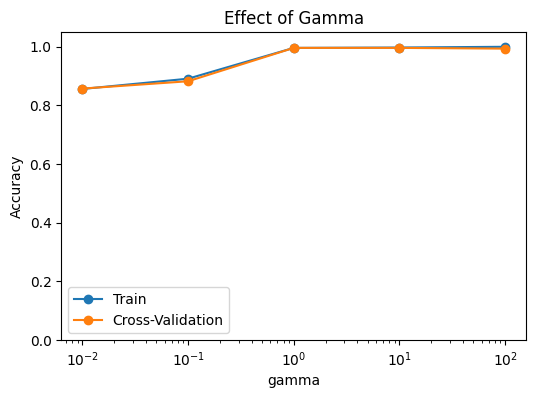

In [6]:
# 다양한 gamma 값에 대해 Train Accuracy와 5-Fold CV Accuracy를 비교한다.
gammas = [0.01, 0.1, 1, 10, 100]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gamma_models = {}
gamma_results = []

for gamma in gammas:
    model = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1, gamma=gamma))
    model.fit(X_train, y_train)

    # Cross-Validation은 X_train 내부만 사용한다.
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    gamma_models[gamma] = model
    gamma_results.append({
        'gamma': gamma,
        'Train Accuracy': model.score(X_train, y_train),
        'CV Accuracy': scores.mean()
    })

result_df = pd.DataFrame(gamma_results)
display(result_df.round(3))

plt.figure(figsize=(6, 4))
plt.semilogx(result_df['gamma'], result_df['Train Accuracy'], 'o-', label='Train')
plt.semilogx(result_df['gamma'], result_df['CV Accuracy'], 'o-', label='Cross-Validation')
plt.xlabel('gamma')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.title('Effect of Gamma')
plt.legend()
plt.show()

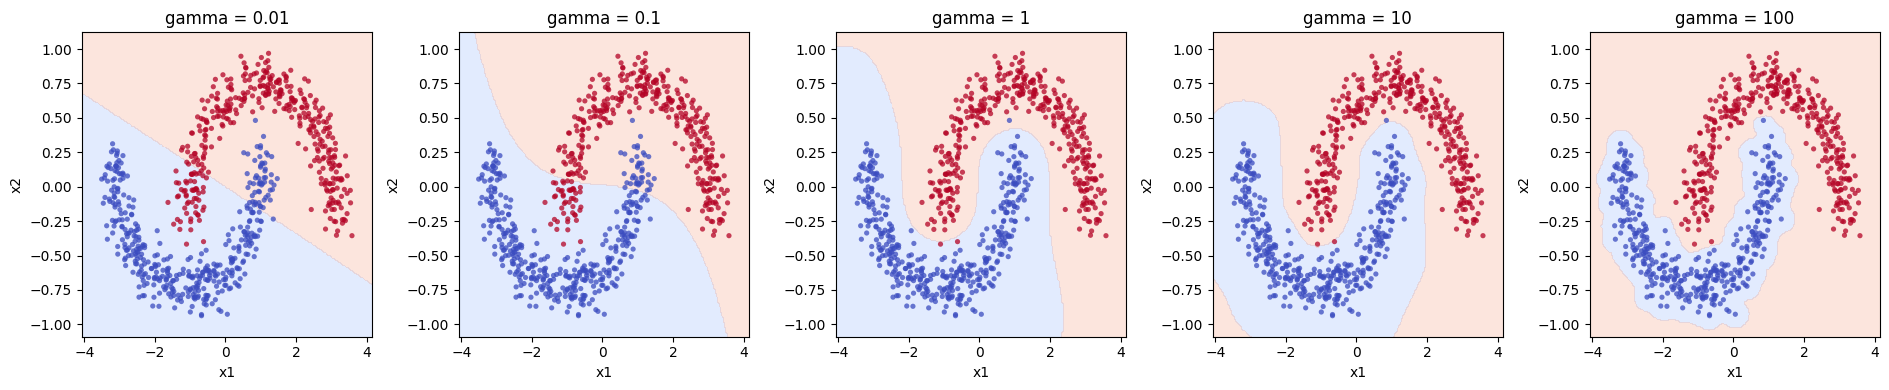

In [7]:
# gamma가 달라질 때 Decision Boundary가 어떻게 달라지는지 확인한다.
fig, axes = plt.subplots(1, len(gammas), figsize=(19, 4))
for ax, gamma in zip(axes, gammas):
    plot_boundary(gamma_models[gamma], X_train, y_train,
                  ax, 'gamma = ' + str(gamma))
plt.tight_layout()
plt.show()

## C and Gamma

21강에서 `C`는 Training Error에 대한 Penalty의 크기를 조절한다고 배웠다.

- 작은 `C`: Margin Violation을 더 허용하는 경향이 있다.
- 큰 `C`: Training Data를 잘못 분류하는 것에 더 큰 Penalty를 준다.
- 작은 `gamma`: RBF의 영향 범위가 넓다.
- 큰 `gamma`: RBF의 영향 범위가 좁다.

두 Parameter가 함께 Decision Boundary를 결정한다.

따라서 `C`만 변경하거나 `gamma`만 변경하는 대신 여러 조합을 비교해 볼 필요가 있다.

그런데 어떤 조합이 좋은지 Test Accuracy로 고른다면, Test Data를 Parameter 선택에 사용한 것이 된다.

## Cross-Validation — Why Do We Need It?

먼저 Data를 Training Data와 Test Data로 분리한다.

Training Data 안에서 5-Fold Cross-Validation을 수행한다.

- Training Data를 다섯 부분으로 나눈다.
- 한 부분은 Validation에, 나머지 네 부분은 학습에 사용한다.
- Validation 부분을 바꿔 가며 다섯 번 반복한다.
- 다섯 Validation Accuracy의 평균으로 Parameter를 평가한다.

`StratifiedKFold`는 각 Fold의 Class 비율이 비슷하도록 나눈다.

주의: Scaling도 각 Fold의 Training 부분에서만 학습해야 한다. `Pipeline`을 사용하면 이 규칙을 지킬 수 있다.

`Test Data`는 Parameter를 결정할 때 사용하지 않고 마지막 Evaluation을 위해 남겨 둔다.

In [8]:
# 하나의 Parameter 조합에 대해 5개의 Validation Accuracy를 확인한다.
example_model = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=1, gamma=1)
)

cv_scores = cross_val_score(
    example_model, X_train, y_train,
    cv=cv, scoring='accuracy'
)

print('Fold Accuracies:', np.round(cv_scores, 3))
print('Mean CV Accuracy:', round(cv_scores.mean(), 3))
print('CV Std:', round(cv_scores.std(), 3))

Fold Accuracies: [1.    0.994 1.    0.994 0.994]
Mean CV Accuracy: 0.996
CV Std: 0.003


## GridSearchCV — Finding C and Gamma

`GridSearchCV`는 지정한 Hyperparameter 조합을 체계적으로 검사한다.

이번 실습에서는

- `C`: 0.1, 1, 10, 100
- `gamma`: 0.01, 0.1, 1, 10

을 사용한다.

조합은 $4\times4=16$개이며, 각 조합에 5-Fold Cross-Validation을 수행하므로 총 80회의 CV Fitting이 이루어진다.

이후 최적 Parameter로 전체 Training Data를 다시 학습하는 Refit이 한 번 더 수행된다.

In [9]:
# Scaling은 각 Fold 내부에서 학습되도록 Pipeline에 포함한다.
pipeline = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf')
)

param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': [0.01, 0.1, 1, 10]
}

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    refit=True,
    return_train_score=True
)

# Test Data를 사용하지 않고 Hyperparameter를 선택한다.
search.fit(X_train, y_train)

print('Best Parameters:', search.best_params_)
print('Best CV Accuracy:', round(search.best_score_, 3))

Best Parameters: {'svc__C': 10, 'svc__gamma': 10}
Best CV Accuracy: 0.997


## Grid Search Results

최적 Parameter 하나만 보는 대신, 모든 `C`와 `gamma` 조합의 평균 Validation Accuracy를 비교한다.

이때 높은 Accuracy를 보인 여러 조합이 비슷할 수도 있다. `best_params_`는 지정한 Grid 안에서 가장 높은 Mean CV Score를 얻은 조합이며, 모든 가능한 Parameter 중 절대적인 최적값이라는 뜻은 아니다.

,C,gamma,Train Accuracy,CV Accuracy,CV Std
15,100.0,10.00,1.000,0.997,0.003
11,10.0,10.00,1.000,0.997,0.003
3,0.1,10.00,0.997,0.996,0.003
7,1.0,10.00,0.998,0.996,0.003
10,10.0,1.00,0.997,0.996,0.003
14,100.0,1.00,1.000,0.996,0.005
6,1.0,1.00,0.996,0.996,0.003
2,0.1,1.00,0.995,0.994,0.004
13,100.0,0.10,0.995,0.994,0.006
9,10.0,0.10,0.980,0.977,0.011


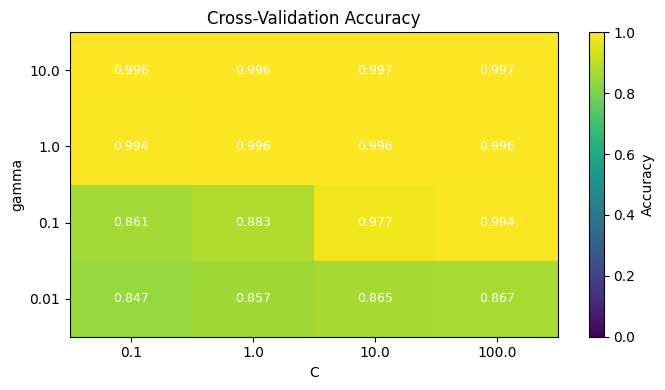

In [10]:
# GridSearchCV의 모든 결과를 DataFrame으로 확인한다.
cv_results = pd.DataFrame(search.cv_results_)
summary = cv_results[[
    'param_svc__C', 'param_svc__gamma',
    'mean_train_score', 'mean_test_score', 'std_test_score'
]].copy()
summary.columns = ['C', 'gamma', 'Train Accuracy', 'CV Accuracy', 'CV Std']
summary[['C', 'gamma']] = summary[['C', 'gamma']].astype(float)
display(summary.sort_values('CV Accuracy', ascending=False).round(3))

# gamma와 C에 따른 CV Accuracy를 Heatmap으로 표시한다.
heatmap = summary.pivot(index='gamma', columns='C', values='CV Accuracy')
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(heatmap.values, origin='lower', aspect='auto',
               cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(len(heatmap.columns)))
ax.set_xticklabels(heatmap.columns)
ax.set_yticks(range(len(heatmap.index)))
ax.set_yticklabels(heatmap.index)
ax.set_xlabel('C')
ax.set_ylabel('gamma')
ax.set_title('Cross-Validation Accuracy')
for i in range(len(heatmap.index)):
    for j in range(len(heatmap.columns)):
        ax.text(j, i, f'{heatmap.iloc[i, j]:.3f}',
                ha='center', va='center', color='white', fontsize=9)
plt.colorbar(im, ax=ax, label='Accuracy')
plt.tight_layout()
plt.show()

## Final Evaluation — Using the Test Data

지금까지 Hyperparameter 선택에 `X_test`와 `y_test`는 사용하지 않았다.

이제 최종 Model을 별도로 보관한 Test Data에서 평가한다.

비교 대상은 다음과 같다.

- Baseline: StandardScaler + RBF SVM (`C=1`, `gamma='scale'`)
- Tuned Model: StandardScaler + GridSearchCV가 선택한 `C`와 `gamma`

Tuning Model이 항상 Baseline보다 Test Accuracy가 높아지는 것은 아니다.

In [11]:
# Baseline도 동일한 Training Data로 학습한다.
baseline = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=1, gamma='scale')
)
baseline.fit(X_train, y_train)

# GridSearchCV의 best_estimator_는 전체 Training Data에 Refit된 Model이다.
tuned_model = search.best_estimator_

print('Baseline Test Accuracy:', round(baseline.score(X_test, y_test), 3))
print('Tuned Test Accuracy   :', round(tuned_model.score(X_test, y_test), 3))
print('Best C:', search.best_params_['svc__C'])
print('Best gamma:', search.best_params_['svc__gamma'])

Baseline Test Accuracy: 1.0
Tuned Test Accuracy   : 1.0
Best C: 10
Best gamma: 10


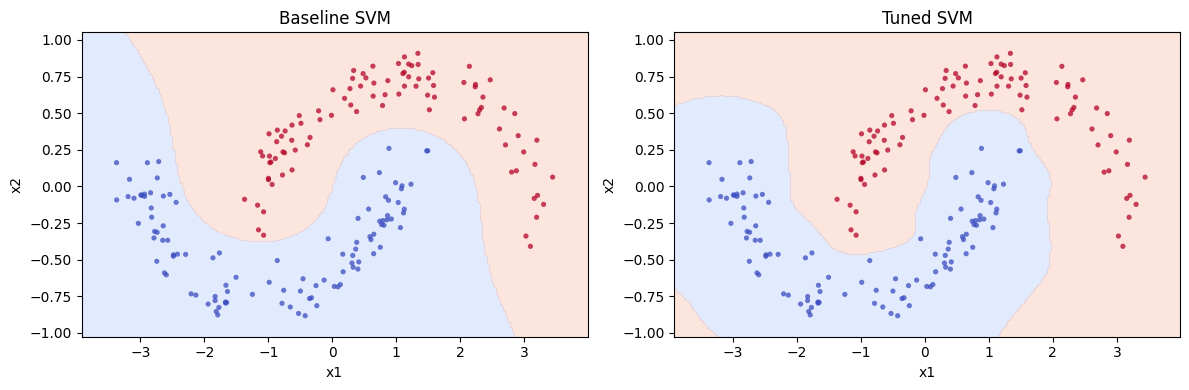

In [12]:
# 두 Model의 Decision Boundary를 같은 좌표계에서 비교한다.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_boundary(baseline, X_test, y_test, axes[0], 'Baseline SVM')
plot_boundary(tuned_model, X_test, y_test, axes[1], 'Tuned SVM')
plt.tight_layout()
plt.show()

## What Did We Learn?

- 같은 Data와 같은 RBF Kernel이라도 Feature Scaling에 따라 결과가 달라질 수 있다.
- `gamma`는 RBF Similarity의 범위를 조절하고, `C`는 오류에 대한 Penalty를 조절한다.
- Train Accuracy가 높다는 것만으로 새로운 Data에서 좋은 Model이라고 판단할 수 없다.
- Cross-Validation으로 Training Data 내부에서 여러 Parameter를 비교한다.
- `GridSearchCV`는 CV Score가 높은 Parameter를 선택하고 Training Data 전체로 다시 학습한다.
- Test Data는 마지막 성능 확인에 사용한다.

이번 강의에서 배운 `Pipeline`, Cross-Validation, Grid Search는 SVM뿐 아니라 다른 ML Model에도 적용할 수 있다.

## Homework — Problem 22

`svm_data2.csv`를 이용하여 RBF SVM의 Hyperparameter를 최적화하시오.

다음 조건을 사용한다.

- Input Features: `x1`, `x2`
- Target: `y`
- `test_size=0.2`, `random_state=42`, `stratify=y`
- `StandardScaler`와 `SVC(kernel='rbf')`를 하나의 Pipeline으로 구성
- `GridSearchCV`: 5-Fold Cross-Validation (`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`)
- `C`: `[0.1, 1, 10, 100]`
- `gamma`: `[0.01, 0.1, 1, 10]`

다음 결과를 적으시오.

- 최적 `C`
- 최적 `gamma`
- 최고 Mean CV Accuracy (소수점 셋째 자리)
- 최적 Model의 Test Accuracy (소수점 셋째 자리)

답만 제출하시오.